In [1]:
import pandas as pd

customers = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/Customer.csv")
geolocation = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/geolocation.csv")
orders = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/orders.csv")
order_items = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/order_items.csv")
payments = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/order_payments.csv")
reviews = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/order_reviews.csv")
products = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/products.csv")
sellers = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/sellers.csv")
category_translation = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/product_category_name_translation.csv")

In [2]:
# Keep original data safe
customers_clean = customers.copy()
geolocation_clean = geolocation.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()
payments_clean = payments.copy()
reviews_clean = reviews.copy()
products_clean = products.copy()
sellers_clean = sellers.copy()
category_translation_clean = category_translation.copy()

# Store all cleaned DataFrames in one dictionary
dfs = {
    "customers": customers_clean,
    "geolocation": geolocation_clean,
    "orders": orders_clean,
    "order_items": order_items_clean,
    "payments": payments_clean,
    "reviews": reviews_clean,
    "products": products_clean,
    "sellers": sellers_clean,
    "category_translation": category_translation_clean
}

print("All 9 datasets copied successfully.")

All 9 datasets copied successfully.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

profile = []

for name, df in dfs.items():
    profile.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Duplicate_Rows": int(df.duplicated().sum()),
        "Missing_Cells": int(df.isnull().sum().sum()),
        "Memory_MB": round(
            df.memory_usage(deep=True).sum() / (1024**2), 2
        )
    })

profile_df = pd.DataFrame(profile)
display(profile_df)

,Dataset,Rows,Columns,Duplicate_Rows,Missing_Cells,Memory_MB
0,customers,99441,5,0,0,26.59
1,geolocation,1000163,5,261836,0,130.26
2,orders,99441,8,0,4908,50.85
3,order_items,112650,7,0,0,35.58
4,payments,103886,5,0,0,16.23
5,reviews,99224,7,0,145903,38.23
6,products,32951,9,0,2448,6.30
7,sellers,3095,4,0,0,0.59
8,category_translation,71,2,0,0,0.01


In [4]:
for name, df in dfs.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name.upper()}")
    print("=" * 60)
    df.info()
    display(df.head(5))


DATASET: CUSTOMERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



DATASET: GEOLOCATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



DATASET: ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


...

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0



DATASET: SELLERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP



DATASET: CATEGORY_TRANSLATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [5]:
missing_report = []

for name, df in dfs.items():
    for col in df.columns:
        missing_count = int(df[col].isnull().sum())

        missing_report.append({
            "Dataset": name,
            "Column": col,
            "Missing_Count": missing_count,
            "Missing_Percentage": round(
                missing_count / len(df) * 100, 2
            ) if len(df) else 0
        })

missing_df = pd.DataFrame(missing_report)

missing_df = missing_df[
    missing_df["Missing_Count"] > 0
].sort_values(
    "Missing_Percentage", ascending=False
)

display(missing_df)

,Dataset,Column,Missing_Count,Missing_Percentage
33,reviews,review_comment_title,87656,88.34
34,reviews,review_comment_message,58247,58.70
16,orders,order_delivered_customer_date,2965,2.98
38,products,product_category_name,610,1.85
39,products,product_name_lenght,610,1.85
40,products,product_description_lenght,610,1.85
41,products,product_photos_qty,610,1.85
15,orders,order_delivered_carrier_date,1783,1.79
14,orders,order_approved_at,160,0.16
42,products,product_weight_g,2,0.01


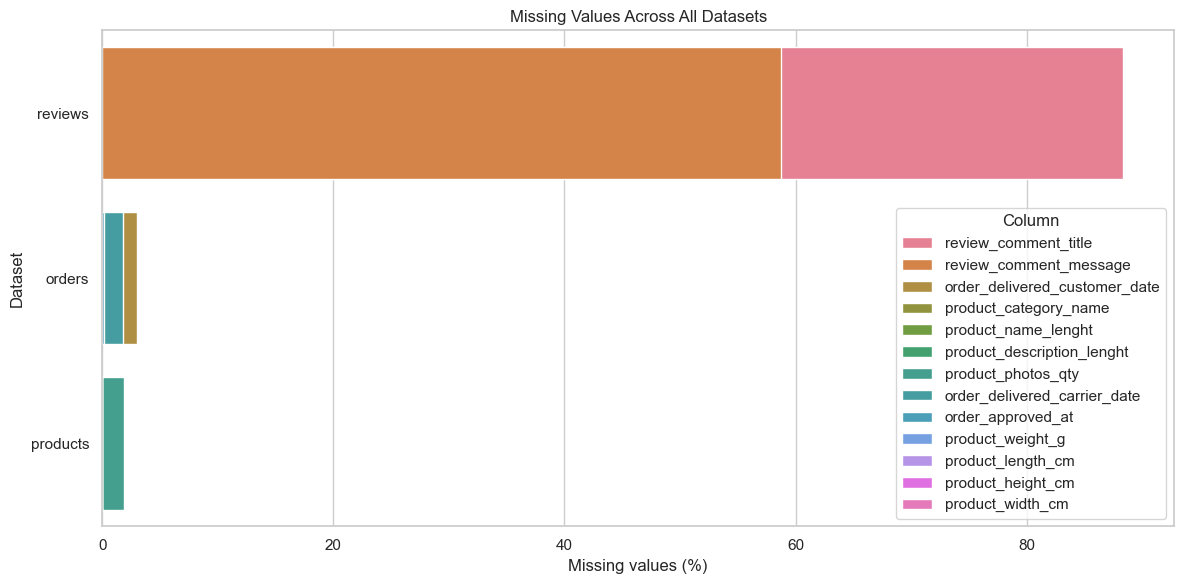

In [6]:
if not missing_df.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=missing_df,
        x="Missing_Percentage",
        y="Dataset",
        hue="Column",
        dodge=False
    )

    plt.title("Missing Values Across All Datasets")
    plt.xlabel("Missing values (%)")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [7]:
duplicate_report = []

for name, df in dfs.items():
    duplicate_report.append({
        "Dataset": name,
        "Full_Duplicate_Rows": int(df.duplicated().sum())
    })

display(pd.DataFrame(duplicate_report))

,Dataset,Full_Duplicate_Rows
0,customers,0
1,geolocation,261836
2,orders,0
3,order_items,0
4,payments,0
5,reviews,0
6,products,0
7,sellers,0
8,category_translation,0


In [8]:
key_columns = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "category_translation": ["product_category_name"]
}

for name, keys in key_columns.items():
    df = dfs[name]

    print(f"\n{name.upper()} — keys: {keys}")
    print("Rows with null key:",
          int(df[keys].isnull().any(axis=1).sum()))
    print("Rows with duplicate key:",
          int(df.duplicated(subset=keys, keep=False).sum()))


CUSTOMERS — keys: ['customer_id']
Rows with null key: 0
Rows with duplicate key: 0

ORDERS — keys: ['order_id']
Rows with null key: 0
Rows with duplicate key: 0

ORDER_ITEMS — keys: ['order_id', 'order_item_id']
Rows with null key: 0
Rows with duplicate key: 0

PAYMENTS — keys: ['order_id', 'payment_sequential']
Rows with null key: 0
Rows with duplicate key: 0

PRODUCTS — keys: ['product_id']
Rows with null key: 0
Rows with duplicate key: 0

SELLERS — keys: ['seller_id']
Rows with null key: 0
Rows with duplicate key: 0

CATEGORY_TRANSLATION — keys: ['product_category_name']
Rows with null key: 0
Rows with duplicate key: 0


In [9]:
for name, df in dfs.items():
    # Standardize column names
    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

    # Remove leading/trailing whitespace from text columns
    text_cols = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for col in text_cols:
        df[col] = df[col].str.strip()

print("Column names and text whitespace standardized.")

Column names and text whitespace standardized.


In [10]:
for col in ["order_status"]:
    if col in dfs["orders"].columns:
        dfs["orders"][col] = (
            dfs["orders"][col].str.lower()
        )

if "payment_type" in dfs["payments"].columns:
    dfs["payments"]["payment_type"] = (
        dfs["payments"]["payment_type"].str.lower()
    )

In [11]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors="coerce"
    )

for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews_clean[col] = pd.to_datetime(
        reviews_clean[col], errors="coerce"
    )

print(orders_clean[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [12]:
date_checks = {
    "Approval before purchase": (
        orders_clean["order_approved_at"]
        < orders_clean["order_purchase_timestamp"]
    ),
    "Carrier delivery before purchase": (
        orders_clean["order_delivered_carrier_date"]
        < orders_clean["order_purchase_timestamp"]
    ),
    "Customer delivery before purchase": (
        orders_clean["order_delivered_customer_date"]
        < orders_clean["order_purchase_timestamp"]
    ),
    "Customer delivery before carrier handoff": (
        orders_clean["order_delivered_customer_date"]
        < orders_clean["order_delivered_carrier_date"]
    )
}

for check_name, condition in date_checks.items():
    print(f"{check_name}: {int(condition.sum())} suspicious rows")

Approval before purchase: 0 suspicious rows
Carrier delivery before purchase: 161 suspicious rows
Customer delivery before purchase: 0 suspicious rows
Customer delivery before carrier handoff: 23 suspicious rows


In [13]:
for name, df in dfs.items():
    numeric_df = df.select_dtypes(include=np.number)

    if not numeric_df.empty:
        print(f"\n{name.upper()}")
        display(numeric_df.describe().T)


CUSTOMERS


,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,99441.0,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0



GEOLOCATION


,count,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,36574.166466,30549.335710,1001.000000,11075.000000,26530.000000,63504.000000,99990.000000
geolocation_lat,1000163.0,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.979620,45.065933
geolocation_lng,1000163.0,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394



ORDER_ITEMS


...

,count,mean,std,min,25%,50%,75%,max
review_score,99224.0,4.086421,1.347579,1.0,4.0,5.0,5.0,5.0



PRODUCTS


,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0



SELLERS


,count,mean,std,min,25%,50%,75%,max
seller_zip_code_prefix,3095.0,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0


In [14]:
print("Negative item prices:",
      (order_items_clean["price"] < 0).sum())

print("Negative freight values:",
      (order_items_clean["freight_value"] < 0).sum())

print("Non-positive item sequence:",
      (order_items_clean["order_item_id"] <= 0).sum())

print("Non-positive payment values:",
      (payments_clean["payment_value"] <= 0).sum())

print("Review scores outside 1–5:",
      (~reviews_clean["review_score"].between(1, 5)).sum())

Negative item prices: 0
Negative freight values: 0
Non-positive item sequence: 0
Non-positive payment values: 9
Review scores outside 1–5: 0


In [15]:
col = "price"

q1 = order_items_clean[col].quantile(0.25)
q3 = order_items_clean[col].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

price_outliers = order_items_clean[
    (order_items_clean[col] < lower_bound) |
    (order_items_clean[col] > upper_bound)
]

print("Price outliers:", len(price_outliers))
display(price_outliers.head(10))

Price outliers: 8427


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,07-10-2018 12:30,810.00,70.75
16,0009c9a17f916a706d71784483a5d643,1,3f27ac8e699df3d300ec4a5d8c5cf0b2,fcb5ace8bcc92f75707dc0f01a27d269,05-02-2018 9:31,639.00,11.34
26,0011d82c4b53e22e84023405fb467e57,1,c389f712c4b4510bc997cee93e8b1a28,bfd27a966d91cfaafdb25d076585f0da,1/29/2018 21:51,289.00,26.33
30,00137e170939bba5a3134e2386413108,1,672e757f331900b9deea127a2a7b79fd,e59aa562b9f8076dd550fcddf0e73491,11/30/2017 6:30,397.00,24.65
39,0017afd5076e074a48f1f1a4c7bac9c5,1,fe59a1e006df3ac42bf0ceb876d70969,25c5c91f63607446a97b143d2d535d31,4/24/2017 22:25,809.10,44.29
61,0025c5d1a8ca53a240ec2634bb4492ea,1,35537536ed2b4c561b4018bf3abf54e0,955fee9216a65b617aa5c0531780ce60,07-10-2018 9:30,390.00,29.39
65,00275bce676303c3bfd7292aefdfa223,1,6490b9f63b0b595e1c1402b46b0f50ad,99eaacc9e6046db1c82b163c5f84869f,12-04-2017 3:32,279.90,13.46
70,0029c5db35ef291ce99d1262012e7daa,1,7614c62b86a81021243e438cfde78ccc,900ba814c251a692506d7834c1218441,09-03-2018 3:50,492.75,21.62
99,0036887767dea4bd43b1a88cd0d9477a,1,3a264b078bf20e98f315ff65c23fa263,46dc3b2cc0980fb8ec44634e21d2718e,10/19/2017 1:07,399.99,23.64
158,006127b8b9a1681a982313ed7129c3c0,1,f819f0c84a64f02d3a5606ca95edd272,7d13fca15225358621be4086e1eb0964,3/15/2018 2:30,540.00,16.22


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

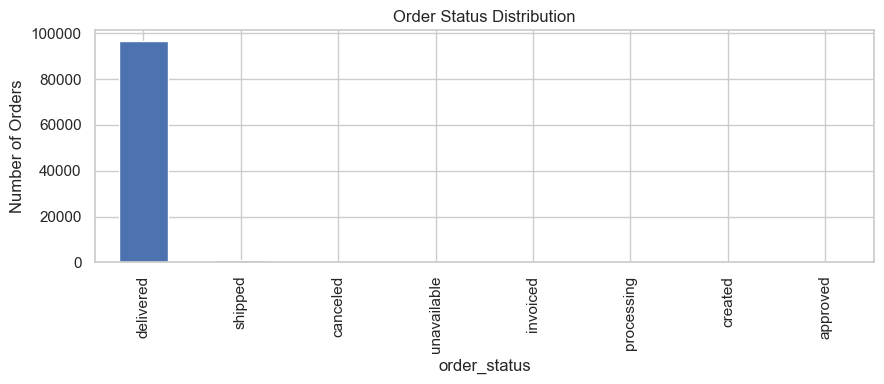

In [16]:
# Order status
display(orders_clean["order_status"].value_counts())

orders_clean["order_status"].value_counts().plot(
    kind="bar", figsize=(9, 4)
)
plt.title("Order Status Distribution")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

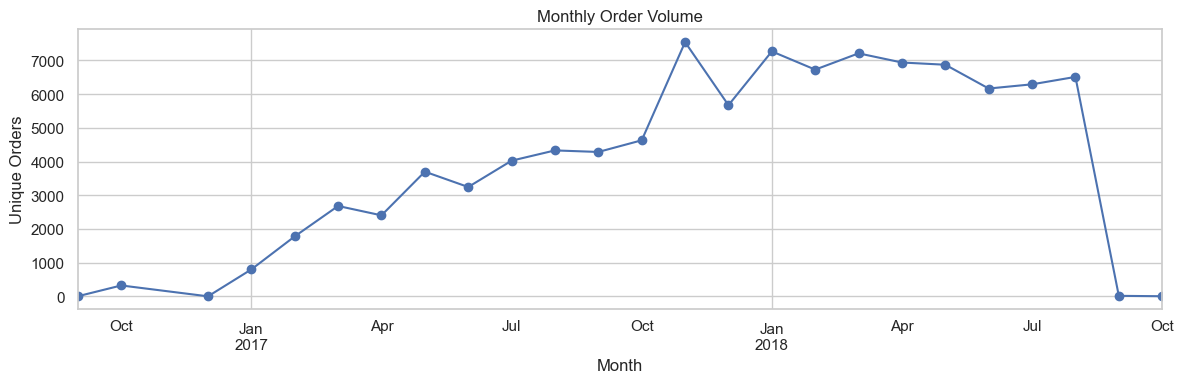

In [17]:
orders_clean["purchase_month"] = (
    orders_clean["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_orders = (
    orders_clean.groupby("purchase_month")["order_id"]
    .nunique()
)

monthly_orders.plot(figsize=(12, 4), marker="o")
plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Unique Orders")
plt.tight_layout()
plt.show()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


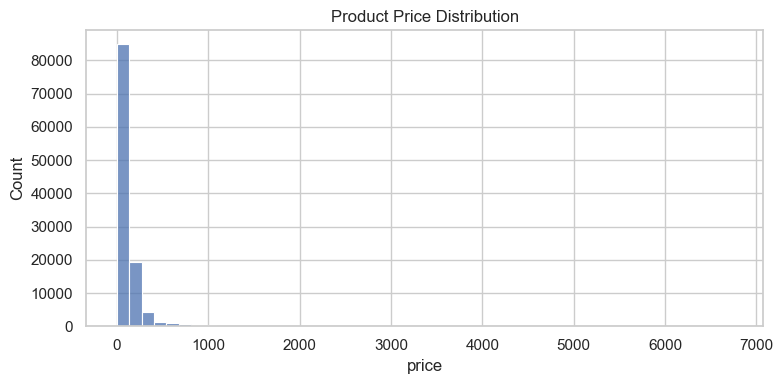

In [18]:
display(
    order_items_clean[["price", "freight_value"]].describe()
)

plt.figure(figsize=(8, 4))
sns.histplot(
    data=order_items_clean,
    x="price",
    bins=50
)
plt.title("Product Price Distribution")
plt.tight_layout()
plt.show()

In [19]:
print("Item revenue:", order_items_clean["price"].sum())
print("Freight total:", order_items_clean["freight_value"].sum())
print("Unique orders with items:",
      order_items_clean["order_id"].nunique())

Item revenue: 13591643.7
Freight total: 2251909.54
Unique orders with items: 98666


payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

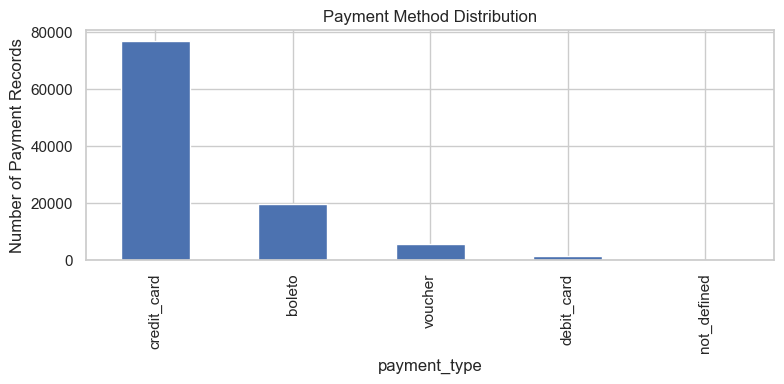

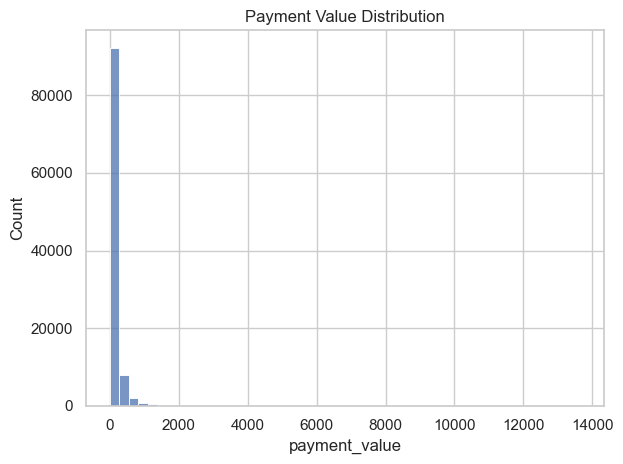

In [20]:
display(payments_clean["payment_type"].value_counts())

payments_clean["payment_type"].value_counts().plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Payment Method Distribution")
plt.ylabel("Number of Payment Records")
plt.tight_layout()
plt.show()

sns.histplot(
    data=payments_clean,
    x="payment_value",
    bins=50
)
plt.title("Payment Value Distribution")
plt.tight_layout()
plt.show()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

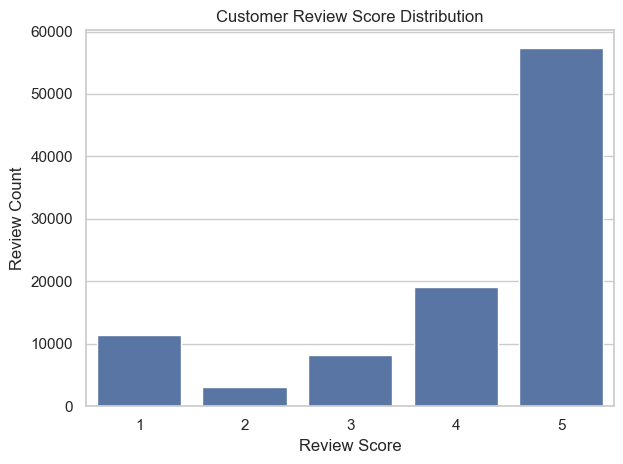

In [21]:
display(
    reviews_clean["review_score"]
    .value_counts()
    .sort_index()
)

sns.countplot(
    data=reviews_clean,
    x="review_score"
)
plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Review Count")
plt.tight_layout()
plt.show()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
Name: count, dtype: int64

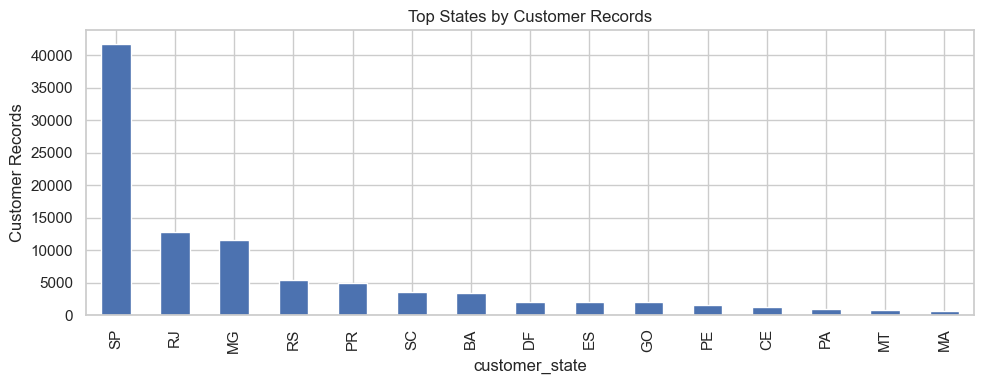

Unique customer identities: 96096


In [22]:
display(
    customers_clean["customer_state"]
    .value_counts()
    .head(15)
)

customers_clean["customer_state"].value_counts().head(15).plot(
    kind="bar", figsize=(10, 4)
)
plt.title("Top States by Customer Records")
plt.ylabel("Customer Records")
plt.tight_layout()
plt.show()

print(
    "Unique customer identities:",
    customers_clean["customer_unique_id"].nunique()
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,32951,32951,1e9e8ef04dbcff4541ed26657ea517e5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,32341,73,cama_mesa_banho,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name_lenght,32341.0,NaN,NaN,NaN,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,NaN,NaN,NaN,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,NaN,NaN,NaN,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,NaN,NaN,NaN,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,NaN,NaN,NaN,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,NaN,NaN,NaN,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,NaN,NaN,NaN,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
fashion_bolsas_e_acessorios     849
papelaria                       849
cool_stuff                      789
Name: count, dtype: int64

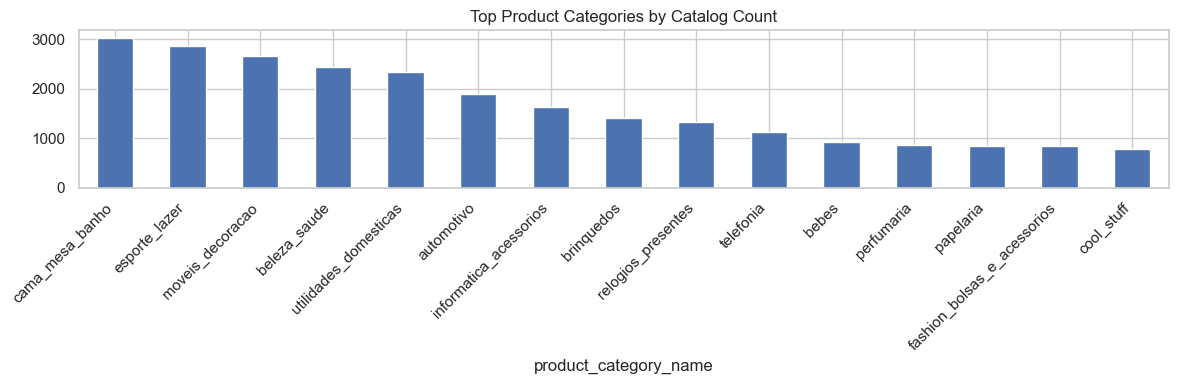

In [23]:
display(products_clean.describe(include="all").T)

display(
    products_clean["product_category_name"]
    .value_counts(dropna=False)
    .head(15)
)

products_clean["product_category_name"].value_counts().head(15).plot(
    kind="bar", figsize=(12, 4)
)
plt.title("Top Product Categories by Catalog Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [24]:
display(
    sellers_clean["seller_state"].value_counts().head(15)
)

print("Unique sellers:", sellers_clean["seller_id"].nunique())

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
Name: count, dtype: int64

Unique sellers: 3095


In [25]:
display(geolocation_clean.describe(include="all").T)

print(
    "Unique ZIP prefixes:",
    geolocation_clean["geolocation_zip_code_prefix"].nunique()
)

print(
    "Duplicate complete rows:",
    geolocation_clean.duplicated().sum()
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,NaN,NaN,NaN,36574.166466,30549.33571,1001.0,11075.0,26530.0,63504.0,99990.0
geolocation_lat,1000163.0,NaN,NaN,NaN,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.97962,45.065933
geolocation_lng,1000163.0,NaN,NaN,NaN,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394
geolocation_city,1000163,8010,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_state,1000163,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Unique ZIP prefixes: 19015
Duplicate complete rows: 261836


In [26]:
invalid_coordinates = geolocation_clean[
    ~geolocation_clean["geolocation_lat"].between(-90, 90) |
    ~geolocation_clean["geolocation_lng"].between(-180, 180)
]

print("Invalid coordinate rows:", len(invalid_coordinates))

Invalid coordinate rows: 0


In [27]:
display(category_translation_clean.head())

print("Rows:", len(category_translation_clean))
print("Duplicate rows:", category_translation_clean.duplicated().sum())
print(
    "Duplicate Portuguese category keys:",
    category_translation_clean.duplicated(
        subset=["product_category_name"],
        keep=False
    ).sum()
)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


Rows: 71
Duplicate rows: 0
Duplicate Portuguese category keys: 0


In [28]:
# Orders without a matching customer
print(
    "Orders with missing customer:",
    (~orders_clean["customer_id"].isin(
        customers_clean["customer_id"]
    )).sum()
)

# Order items without a matching order
print(
    "Items with missing order:",
    (~order_items_clean["order_id"].isin(
        orders_clean["order_id"]
    )).sum()
)

# Order items without a matching product
print(
    "Items with missing product:",
    (~order_items_clean["product_id"].isin(
        products_clean["product_id"]
    )).sum()
)

# Order items without a matching seller
print(
    "Items with missing seller:",
    (~order_items_clean["seller_id"].isin(
        sellers_clean["seller_id"]
    )).sum()
)

# Payments without a matching order
print(
    "Payments with missing order:",
    (~payments_clean["order_id"].isin(
        orders_clean["order_id"]
    )).sum()
)

Orders with missing customer: 0
Items with missing order: 0
Items with missing product: 0
Items with missing seller: 0
Payments with missing order: 0


In [29]:
# Aggregate order items to one row per order
item_summary = (
    order_items_clean.groupby("order_id")
    .agg(
        item_revenue=("price", "sum"),
        freight_total=("freight_value", "sum"),
        item_count=("order_item_id", "count")
    )
    .reset_index()
)

# Aggregate payments to one row per order
payment_summary = (
    payments_clean.groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum"),
        payment_count=("payment_sequential", "count")
    )
    .reset_index()
)

# Aggregate review scores to one row per order
review_summary = (
    reviews_clean.groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_id", "count")
    )
    .reset_index()
)

# Build the master table
master = (
    orders_clean
    .merge(
        customers_clean,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        item_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        payment_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        review_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

print("Orders:", len(orders_clean))
print("Master rows:", len(master))
print("Unique master orders:", master["order_id"].nunique())

display(master.head())

Orders: 99441
Master rows: 99441
Unique master orders: 99441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,item_revenue,freight_total,item_count,payment_total,payment_count,average_review_score,review_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:00,2017-10-02 11:07:00,2017-10-04 19:55:00,2017-10-10 21:25:00,2017-10-18,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.99,8.72,1.0,38.71,3.0,4.0,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:00,2018-07-26 03:24:00,2018-07-26 14:31:00,2018-08-07 15:27:00,2018-08-13,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.70,22.76,1.0,141.46,1.0,4.0,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,2018-08-08 08:55:00,2018-08-08 13:50:00,2018-08-17 18:06:00,2018-09-04,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.90,19.22,1.0,179.12,1.0,5.0,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:00,2017-11-18 19:45:00,2017-11-22 13:39:00,2017-12-02 00:28:00,2017-12-15,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.00,27.20,1.0,72.20,1.0,5.0,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:00,2018-02-13 22:20:00,2018-02-14 19:46:00,2018-02-16 18:17:00,2018-02-26,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.90,8.72,1.0,28.62,1.0,5.0,1.0


In [30]:
master["delivery_days"] = (
    master["order_delivered_customer_date"]
    - master["order_purchase_timestamp"]
).dt.total_seconds() / 86400

master["delay_days"] = (
    master["order_delivered_customer_date"]
    - master["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivered = master[
    master["order_status"].eq("delivered")
].copy()

print("Average delivery days:", delivered["delivery_days"].mean())
print("Median delivery days:", delivered["delivery_days"].median())

delivered["late_delivery"] = delivered["delay_days"] > 0

print(
    "Late delivery rate (%):",
    round(delivered["late_delivery"].mean() * 100, 2)
)

Average delivery days: 12.558173691015053
Median delivery days: 10.217708333333334
Late delivery rate (%): 8.11


In [31]:
review_by_delivery = (
    delivered.groupby("late_delivery")["average_review_score"]
    .agg(["count", "mean", "median"])
)

display(review_by_delivery)

,count,mean,median
late_delivery,,,
False,88171,4.294311,5.0
True,7661,2.566506,2.0


In [32]:
reconciliation = item_summary.merge(
    payment_summary,
    on="order_id",
    how="outer",
    indicator=True
)

reconciliation["expected_item_freight"] = (
    reconciliation["item_revenue"]
    + reconciliation["freight_total"]
)

reconciliation["payment_difference"] = (
    reconciliation["payment_total"]
    - reconciliation["expected_item_freight"]
)

display(
    reconciliation.assign(
        absolute_difference=lambda x:
            x["payment_difference"].abs()
    ).sort_values(
        "absolute_difference", ascending=False
    ).head(20)
)

,order_id,item_revenue,freight_total,item_count,payment_total,payment_count,_merge,expected_item_freight,payment_difference,absolute_difference
80176,ce6d150fb29ada17d2082f4847107665,1299.00,104.66,1.0,1586.47,1.0,both,1403.66,182.81,182.81
42865,6e5fe7366a2e1bfbf3257dba0af1267f,179.19,108.72,6.0,406.92,1.0,both,287.91,119.01,119.01
43791,70b742795bc441e94a44a084b6d9ce7a,269.99,196.94,1.0,578.82,1.0,both,466.93,111.89,111.89
59228,996c7e73600ad3723e8627ab7bef81e4,559.90,28.00,1.0,664.43,1.0,both,587.90,76.53,76.53
43794,70b7e94ea46d3e8b5bc12a50186edaf0,167.88,45.27,3.0,274.84,1.0,both,213.15,61.69,61.69
73090,bc2c82b0ef78d2252b6176d1972db7c9,165.00,77.01,3.0,303.02,1.0,both,242.01,61.01,61.01
68015,af9ffff2ce6b3defd34fd4c78857a379,395.65,17.52,1.0,466.97,1.0,both,413.17,53.80,53.80
14745,262118ce178bb3e4590a3adcf6d62e6b,119.80,57.94,2.0,126.12,1.0,both,177.74,-51.62,51.62
74503,bfdb5bbb06458d600a33d61f5f287472,297.00,51.93,1.0,394.36,1.0,both,348.93,45.43,45.43
54744,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,209.80,44.65,2.0,293.89,1.0,both,254.45,39.44,39.44


In [33]:
from pathlib import Path

output_dir = Path("olist_eda_outputs")
output_dir.mkdir(exist_ok=True)

for name, df in dfs.items():
    df.to_csv(
        output_dir / f"{name}_cleaned.csv",
        index=False
    )

profile_df.to_csv(
    output_dir / "data_profile.csv",
    index=False
)

missing_df.to_csv(
    output_dir / "missing_values_report.csv",
    index=False
)

reconciliation.to_csv(
    output_dir / "payment_reconciliation.csv",
    index=False
)

master.to_csv(
    output_dir / "master_analytical_dataset.csv",
    index=False
)

print("Exports saved to:", output_dir.resolve())

Exports saved to: C:\Users\kunja\Downloads\olist_eda_outputs


# Predictive Model using your 9 Olist data files

In [34]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit

  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.35.0
    Uninstalling protobuf-7.35.0:
      Successfully uninstalled protobuf-7.35.0
Note: you may need to restart the kernel to use updated packages.


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from pathlib import Path

In [36]:
orders_ml = orders.copy()
items_ml = order_items.copy()
customers_ml = customers.copy()
products_ml = products.copy()
sellers_ml = sellers.copy()

date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders_ml[col] = pd.to_datetime(
        orders_ml[col], errors="coerce"
    )

print("Orders:", orders_ml.shape)
print("Items:", items_ml.shape)

Orders: (99441, 8)
Items: (112650, 7)


In [37]:
item_summary = (
    items_ml.groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        item_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        seller_count=("seller_id", "nunique"),
        product_count=("product_id", "nunique")
    )
    .reset_index()
)

In [38]:
customer_features = customers_ml[
    ["customer_id", "customer_state"]
].drop_duplicates("customer_id")

In [39]:
ml_data = orders_ml.merge(
    item_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

ml_data = ml_data.merge(
    customer_features,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Keep orders with observed delivery outcomes
ml_data = ml_data[
    ml_data["order_status"].eq("delivered")
    & ml_data["order_delivered_customer_date"].notna()
    & ml_data["order_estimated_delivery_date"].notna()
].copy()

ml_data["late_delivery"] = (
    ml_data["order_delivered_customer_date"]
    > ml_data["order_estimated_delivery_date"]
).astype(int)

print(ml_data["late_delivery"].value_counts())
print(ml_data["late_delivery"].value_counts(normalize=True).round(3))

late_delivery
0    88644
1     7826
Name: count, dtype: int64
late_delivery
0    0.919
1    0.081
Name: proportion, dtype: float64


In [40]:
ml_data["purchase_month"] = (
    ml_data["order_purchase_timestamp"].dt.month
)

ml_data["purchase_day_of_week"] = (
    ml_data["order_purchase_timestamp"].dt.dayofweek
)

ml_data["purchase_hour"] = (
    ml_data["order_purchase_timestamp"].dt.hour
)

ml_data["estimated_delivery_days"] = (
    ml_data["order_estimated_delivery_date"]
    - ml_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

ml_data["estimated_delivery_days"] = (
    ml_data["estimated_delivery_days"].clip(lower=0)
)

In [41]:
feature_cols = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "estimated_delivery_days",
    "item_count",
    "item_value",
    "freight_value",
    "seller_count",
    "product_count"
]

X = ml_data[feature_cols].copy()
y = ml_data["late_delivery"].copy()

print("Features:", X.shape)
print("Target:", y.shape)

Features: (96470, 10)
Target: (96470,)


In [42]:
ml_data = ml_data.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

X = ml_data[feature_cols]
y = ml_data["late_delivery"]

split_index = int(len(ml_data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training late rate:", round(y_train.mean(), 3))
print("Testing late rate:", round(y_test.mean(), 3))

Training rows: 77176
Testing rows: 19294
Training late rate: 0.088
Testing late rate: 0.053


In [43]:
categorical_features = ["customer_state"]

numeric_features = [
    col for col in feature_cols
    if col not in categorical_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [44]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [45]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [46]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC AUC": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2 else np.nan
        )
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Logistic Regression,0.5563,0.0929,0.8423,0.1673,0.7223
Random Forest,0.8968,0.0917,0.1068,0.0986,0.7337


Model selected by test F1-score: Logistic Regression


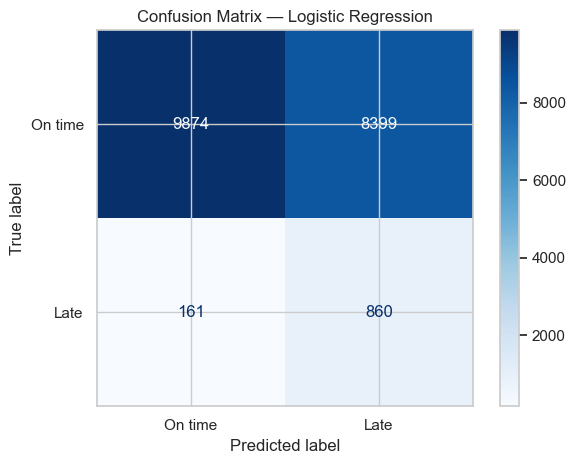

In [47]:
best_model_name = results_df["F1 Score"].idxmax()
best_model = models[best_model_name]

print("Model selected by test F1-score:", best_model_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_model.predict(X_test),
    display_labels=["On time", "Late"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

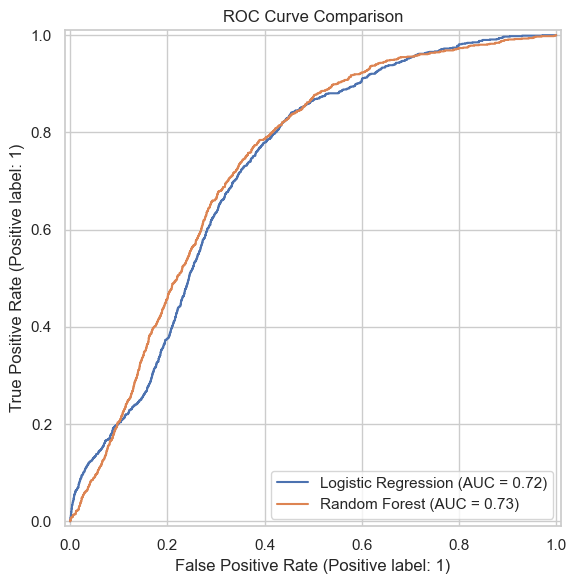

In [48]:
if y_test.nunique() == 2:
    fig, ax = plt.subplots(figsize=(7, 6))

    for name, model in models.items():
        RocCurveDisplay.from_estimator(
            model, X_test, y_test,
            name=name, ax=ax
        )

    plt.title("ROC Curve Comparison")
    plt.tight_layout()
    plt.show()

,Feature,Importance
3,numeric__estimated_delivery_days,0.215820
0,numeric__purchase_month,0.169423
6,numeric__freight_value,0.164967
5,numeric__item_value,0.134595
2,numeric__purchase_hour,0.088834
1,numeric__purchase_day_of_week,0.056209
34,categorical__customer_state_SP,0.044503
27,categorical__customer_state_RJ,0.024165
19,categorical__customer_state_MG,0.015960
4,numeric__item_count,0.010611


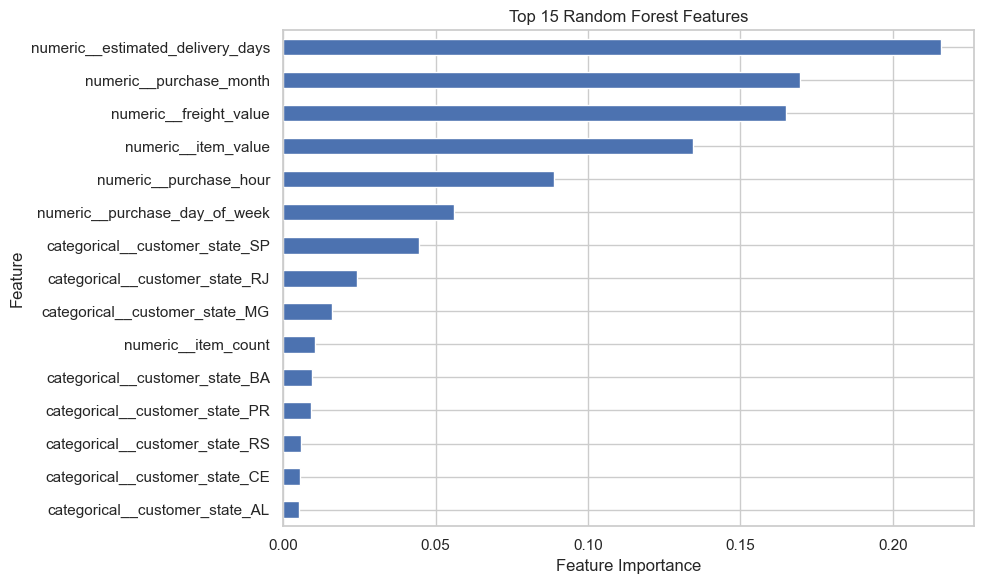

In [49]:
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
importances = rf_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

importance_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Random Forest Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [50]:
output_dir = Path("model_artifacts")
output_dir.mkdir(exist_ok=True)

joblib.dump(
    {
        "model": best_model,
        "features": feature_cols,
        "model_name": best_model_name,
        "target_definition": (
            "1 if actual delivery date is after estimated delivery date"
        )
    },
    output_dir / "late_delivery_model.joblib"
)

print("Model saved successfully.")

Model saved successfully.
